In [1]:
from cropspectai import ml_config
from cropspectai.data_analysis import preprocessing
from cropspectai.modeling.train import train_model

import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor


# --------------------------------------------------
# Load data
# --------------------------------------------------

spectral_length = "as7343" # "full" or "1000" or "as7343"
target = "cab" # "cab" or None
indices = "all" # "all" or "established" or None

if spectral_length == "as7343":
    if target == None:
        train_path = (
            ml_config.PROCESSED_PARQUET_DATA_SPLITS_PATH
            / "all"
            / "train.parquet"
        )
    elif target == "cab":
        if indices == "all": # all engineered features
            train_path = (
                        ml_config.PROCESSED_PARQUET_DATA_SPLITS_PATH
                        / target
                        / "train_all_features.parquet"
                    )
        elif indices == "established": # only established new features
            train_path = (
                        ml_config.PROCESSED_PARQUET_DATA_SPLITS_PATH
                        / target
                        / "train_established_features.parquet"
                    ) 
        elif indices == None: # no engineered features
            train_path = (
                        ml_config.PROCESSED_PARQUET_DATA_SPLITS_PATH
                        / target
                        / "train.parquet"
                    )       
elif spectral_length == "full" or "1000":
    train_path = (
        ml_config.RAW_PARQUET_DATA_SPLITS_PATH
        / "train.parquet"
    )

df = pd.read_parquet(train_path)
print("Shape of imported data: ", df.shape)

/Users/sharanashivanand/git_repos/dsr/cropspectai/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape of imported data:  (1607, 41)


In [2]:
# --------------------------------------------------
# Get feature and target column names
# --------------------------------------------------

X, y = preprocessing.split_dataset_into_X_y(df, target)

targets = y.columns.tolist()

print("Targets:")
print(targets)

Targets:
['cab']


## Hyperspectra up to 1000nm only

In [3]:
if spectral_length == "1000":
    print(X.shape)
    X_1000 = X.loc[:, "400":"1000"].copy()
    print(X_1000.shape)
    print(y.shape)

    df = pd.concat([X_1000, y], axis = 1).copy()
    print(df.shape)

In [4]:
# --------------------------------------------------
# Store results
# --------------------------------------------------

results = {}


# --------------------------------------------------
# Run XGBoost independently for every target
# --------------------------------------------------

for target in targets:

    print("\n" + "=" * 60)
    print(f"TARGET: {target}")
    print("=" * 60)

    # IMPORTANT:
    # Start from the original dataframe for every target
    df_target = preprocessing.drop_duplicates(
        df,
        target
    ).copy()

    # Split into features and targets AFTER target-specific
    # duplicate handling
    X, y = preprocessing.split_dataset_into_X_y(df_target, target)

    # Train / validation split
    X_train, X_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
    )

    # Create a fresh model for every target
    model_xgb = XGBRegressor(
        n_estimators=1000,
        max_depth=6,
        learning_rate=0.01,
        subsample=0.8,
        colsample_bytree=1.0,

        tree_method="hist",

        objective="reg:squarederror",
        eval_metric="rmse",

        n_jobs=-1,
        random_state=42,
    )

    # Train
    pipeline_xgb, metrics = train_model(
        model_xgb,
        X_train,
        y_train,
        X_val,
        y_val,
        scale=False,
    )

    metrics["Samples"] = len(df_target)
    results[target] = metrics


TARGET: cab
(Before) Shape of dataframe: (1607, 41)
Dropping duplicate rows
Duplicate rows: 1
(After) Shape of dataframe: (1606, 41)
Checking for rows without labels
Rows with no labels: 0 with target: cab
(After) Shape of dataframe: (1606, 41)


In [5]:
# --------------------------------------------------
# Create results table
# --------------------------------------------------

results_df = pd.DataFrame(results)
print("\nXGBoost Results for each target")
print(results_df)


XGBoost Results for each target
                          cab
MAE (train)          1.952153
MAPE (train) [%]     6.206918
RMSE (train)         2.587906
MAE (test)           6.865679
MAPE (test) [%]     19.940136
RMSE (test)          9.893788
R² (test)            0.534239
Samples           1606.000000


## SHAP analysis

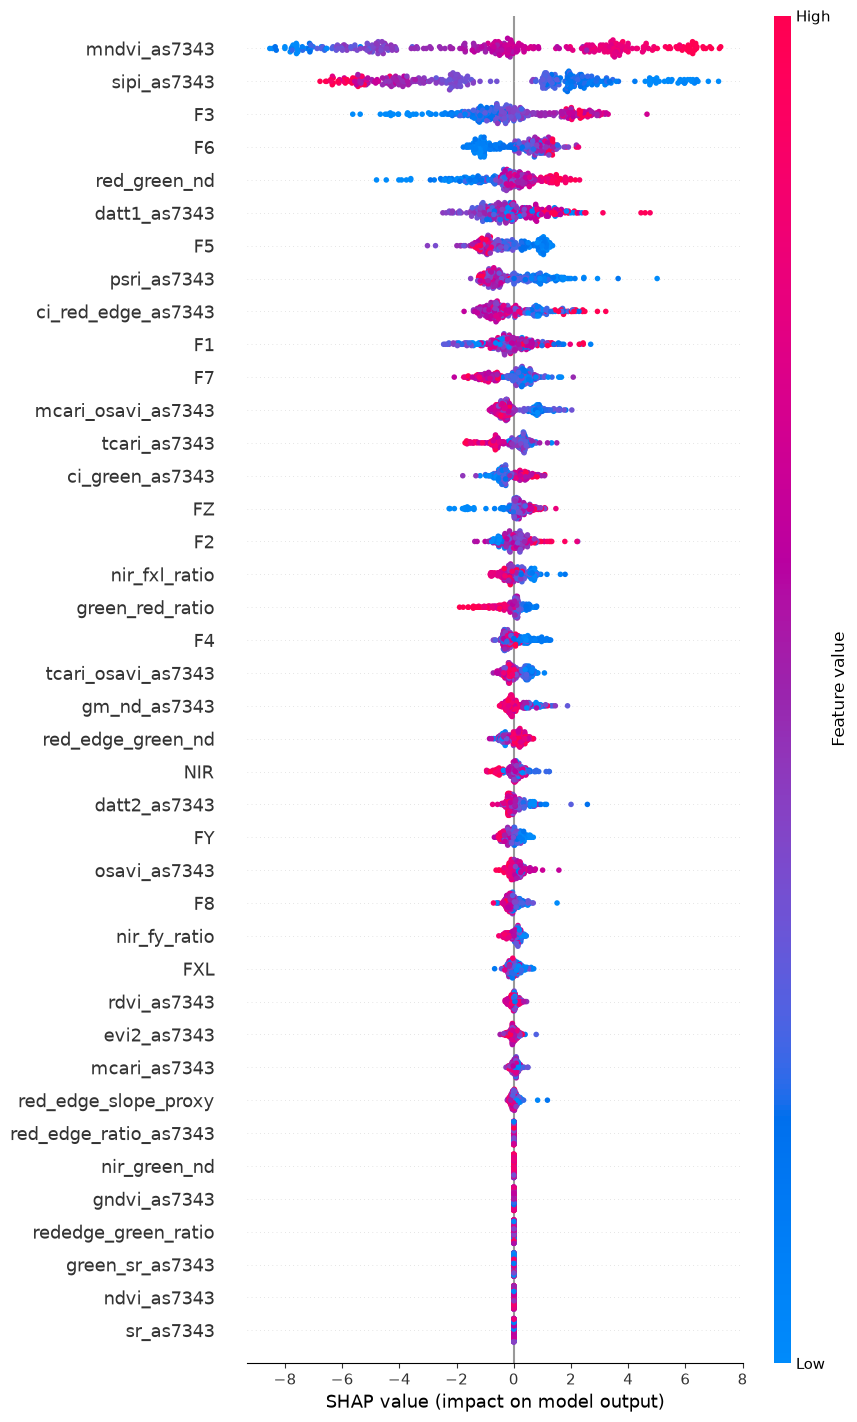

In [6]:
model = pipeline_xgb.named_steps["model"]
explainer = shap.TreeExplainer(model)

shap_values = explainer(X_val)
shap.plots.beeswarm(
    shap_values,
    max_display=40,
)

In [7]:
shap_importance = pd.DataFrame({
    "feature": X_val.columns,
    "mean_abs_shap": abs(shap_values.values).mean(axis=0),
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False,
)

print(shap_importance)

                  feature  mean_abs_shap
23           mndvi_as7343       3.650515
30            sipi_as7343       3.299764
3                      F3       1.385949
8                      F6       0.905910
32           red_green_nd       0.842295
17           datt1_as7343       0.833939
6                      F5       0.797600
31            psri_as7343       0.795559
12     ci_red_edge_as7343       0.784420
0                      F1       0.638101
9                      F7       0.563884
21     mcari_osavi_as7343       0.503509
19           tcari_as7343       0.466787
13        ci_green_as7343       0.386002
2                      FZ       0.353611
1                      F2       0.346051
39          nir_fxl_ratio       0.329862
36        green_red_ratio       0.321360
4                      F4       0.311319
22     tcari_osavi_as7343       0.294756
14           gm_nd_as7343       0.279501
33      red_edge_green_nd       0.252876
11                    NIR       0.239722
16           dat

In [8]:
# file_name = f"xgboost_results_{target}_{spectral_length}-{indices}.csv"
# output_path = ml_config.REPORTS_DIR / file_name

# results_df.to_csv(
#     output_path,
#     index=True,
# )

- full length hyperspectra gives better R2 score for all targets except CAB
- 1000nm cutoff hyperspectra gives consistently lower R2 score than full except for CAB
- as7343 does poor at all targets and consistently lower than 1000nm 
 - but CAB score remains on par with 1000nm
 - more importantly does better than even full

Conclusion:
- CAB is better predicted with data within 1000nm range
- as7343 is better capable at predicting CAB than all other targets